# Когорты и удержание: сравнение определений

Клиент активен в месяце, если месяц пересекается с интервалом действия подписки (от даты транзакции до
`membership_expire_date`, транзакции без отмен, дата окончания обрезана концом наблюдений 31.03.2017).
Теория: `docs/cohorts_and_retention.md`. Здесь сравниваются:

1. привязка когорты: месяц регистрации, месяц первой подписки (включая пробную), месяц первой платной подписки;
2. строгое удержание (подписка не прерывалась) и удержание с возвратами;
3. влияние левого цензурирования: клиенты, подписавшиеся до начала данных (01.01.2015), выглядят в начале периода как новые.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

P = "/workspace/data/processed/"
LAST_MONTH = pd.Timestamp("2017-03-01")
INK = "#2b2f36"
# цвета Окабе-Ито: различимы при всех основных видах дальтонизма
BLUE, ORANGE, GREEN, GRAY = "#0072B2", "#E69F00", "#009E73", "#8a8f98"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute(
    "SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false; "
    "SET temp_directory='/workspace/data/_duckdb_tmp'"
)
con.execute(f'''
    CREATE VIEW act AS
    SELECT *
    FROM '{P}active_months.parquet'
''')
_ = con.execute(f'''
    CREATE VIEW anc AS
    SELECT *
    FROM '{P}user_anchors.parquet'
''')

## Левое цензурирование
Доля клиентов, зарегистрированных до 2015 года, среди тех, чья первая подписка в данных приходится на месяц когорты.
Если доля высокая, когорта состоит не из новых клиентов, а из старых, которых данные заметили впервые.

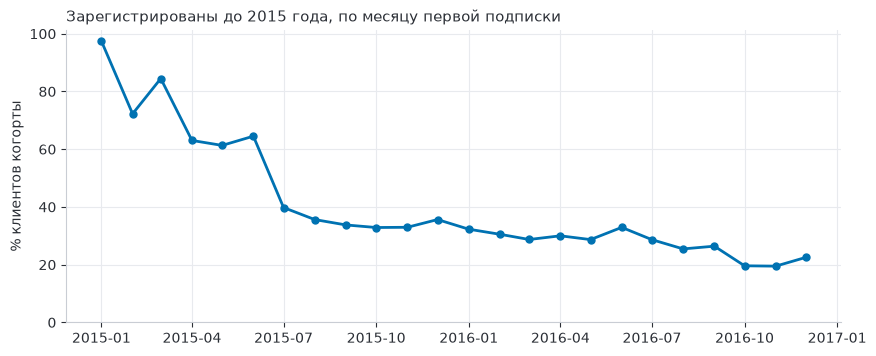

' cohort      n  share_registered_before_2015  share_without_profile\n2015-01 535737                         0.975                  0.096\n2015-02  48677                         0.723                  0.041\n2015-03 119564                         0.845                  0.092\n2015-04  48315                         0.630                  0.122\n2015-05  45100                         0.613                  0.134\n2015-06 179707                         0.645                  0.093\n2015-07  61033                         0.398                  0.270\n2015-08  72839                         0.356                  0.276\n2015-09  71990                         0.338                  0.302\n2015-10  86671                         0.329                  0.317\n2015-11  98053                         0.329                  0.370\n2015-12  96125                         0.356                  0.388'

In [2]:
diag = con.sql('''
    SELECT
        first_sub_month AS cohort,
        count(*) AS n,
        avg((reg_month < DATE '2015-01-01')::int) AS share_registered_before_2015,
        avg((reg_month IS NULL)::int) AS share_without_profile
    FROM anc
    WHERE first_sub_month BETWEEN DATE '2015-01-01' AND DATE '2016-12-01'
    GROUP BY 1
    ORDER BY 1
''').df()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(diag.cohort, 100 * diag.share_registered_before_2015, color=BLUE, lw=2, marker="o", ms=5)
ax.set_ylabel("% клиентов когорты")
ax.set_title("Зарегистрированы до 2015 года, по месяцу первой подписки", loc="left", fontsize=11)
ax.set_ylim(0, None)
plt.show()
diag.assign(cohort=diag.cohort.dt.strftime("%Y-%m")).round(3).head(12).to_string(index=False)

## Три привязки когорты, удержание с возвратами
Средняя кривая по когортам, полностью наблюдаемым на горизонте 12 месяцев (с 2015-07 по 2016-03).
Доля считается от размера когорты. Для регистрации возраст 0 это месяц регистрации, и подписка в нём действует
далеко не у всех. Вариант «первая подписка, зарегистрированы с 2015 года» убирает старых клиентов.

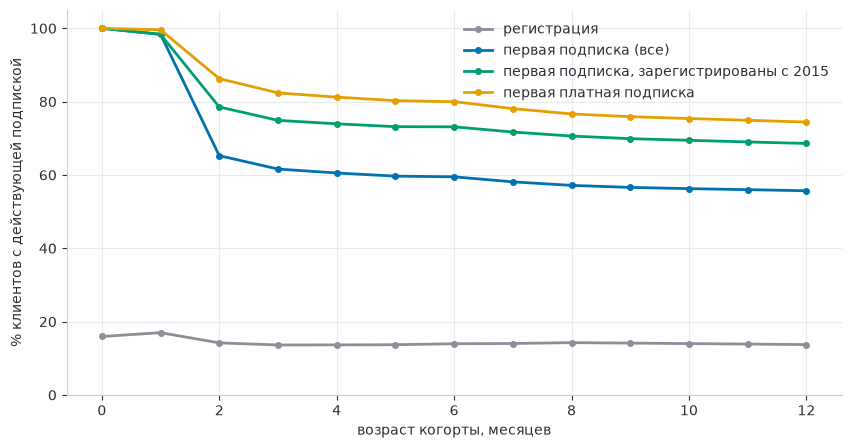

,регистрация,первая подписка (все),"первая подписка, зарегистрированы с 2015",первая платная подписка
age,,,,
0,15.9,100.0,100.0,100.0
1,17.0,98.4,98.3,99.6
3,13.6,61.6,74.9,82.4
6,14.0,59.5,73.1,80.0
12,13.7,55.7,68.6,74.4


In [3]:
C_FROM, C_TO, MAX_AGE = "2015-07-01", "2016-03-01", 12


def returns_curve(anchor: str, c_from: str, c_to: str, max_age: int = 12, extra: str = "") -> pd.Series:
    '''Считает среднюю по когортам долю активных клиентов по возрасту (с возвратами).

    Args:
        anchor (str): столбец привязки когорты в таблице `anc`.
        c_from (str): первая когорта (первый день месяца).
        c_to (str): последняя когорта (первый день месяца).
        max_age (int): максимальный возраст в месяцах.
        extra (str): дополнительное условие SQL для отбора клиентов.

    Returns:
        pd.Series: доля активных клиентов, индекс это возраст в месяцах.
    '''
    df = con.sql(f'''
        WITH coh AS (
            SELECT
                msno,
                {anchor} AS cohort
            FROM anc
            WHERE {anchor} BETWEEN DATE '{c_from}' AND DATE '{c_to}'
                {extra}
        ),
        coh_size AS (
            SELECT count(*) AS size
            FROM coh
        )
        SELECT
            date_diff('month', coh.cohort, act.month) AS age,
            count(*) AS active,
            any_value(coh_size.size) AS size
        FROM coh
        JOIN act USING (msno)
        CROSS JOIN coh_size
        WHERE act.month >= coh.cohort
            AND date_diff('month', coh.cohort, act.month) <= {max_age}
        GROUP BY 1
        ORDER BY 1
    ''').df()
    return df.set_index("age").active / df["size"].iloc[0]


variants = {
    "регистрация": dict(anchor="reg_month"),
    "первая подписка (все)": dict(anchor="first_sub_month"),
    "первая подписка, зарегистрированы с 2015": dict(anchor="first_sub_month", extra="AND reg_month >= DATE '2015-01-01'"),
    "первая платная подписка": dict(anchor="first_paid_month"),
}
curves = pd.DataFrame({name: returns_curve(c_from=C_FROM, c_to=C_TO, max_age=MAX_AGE, **kw)
                       for name, kw in variants.items()})

colors = [GRAY, BLUE, GREEN, ORANGE]
fig, ax = plt.subplots(figsize=(10, 5))
for (name, s), col in zip(curves.items(), colors):
    ax.plot(s.index, 100 * s, color=col, lw=2, marker="o", ms=4, label=name)
ax.set_xlabel("возраст когорты, месяцев")
ax.set_ylabel("% клиентов с действующей подпиской")
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="upper right")
plt.show()
(100 * curves.loc[[0, 1, 3, 6, 12]]).round(1)

## Строгое удержание и удержание с возвратами
Строгое: клиент удержан, пока подписка не прерывалась ни на один месяц. С возвратами: клиент, ушедший и вернувшийся,
снова считается активным. Разница между кривыми это доля вернувшихся.

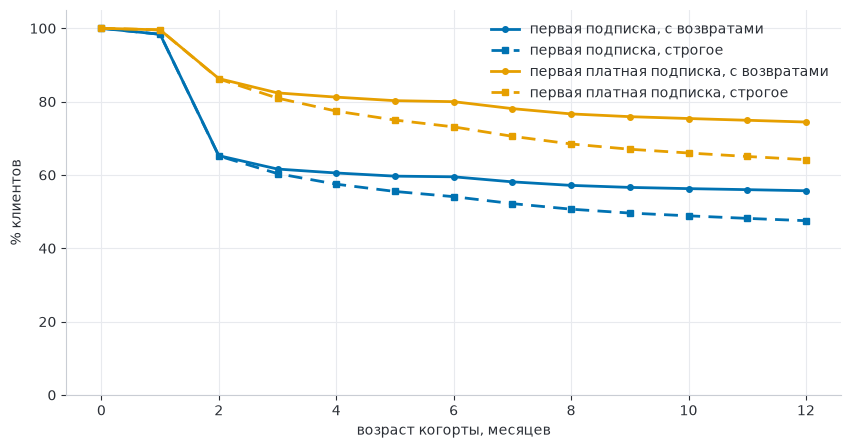

,"первая подписка, с возвратами","первая подписка, строгое","первая платная подписка, с возвратами","первая платная подписка, строгое"
age,,,,
1,98.4,98.4,99.6,99.6
3,61.6,60.4,82.4,81.0
6,59.5,54.1,80.0,73.1
12,55.7,47.5,74.4,64.2


In [4]:
def strict_curve(anchor: str, c_from: str, c_to: str, max_age: int = 12, extra: str = "") -> pd.Series:
    '''Считает среднюю по когортам долю клиентов, подписка которых не прерывалась (строгое удержание).

    Args:
        anchor (str): столбец привязки когорты в таблице `anc`.
        c_from (str): первая когорта (первый день месяца).
        c_to (str): последняя когорта (первый день месяца).
        max_age (int): максимальный возраст в месяцах.
        extra (str): дополнительное условие SQL для отбора клиентов.

    Returns:
        pd.Series: доля клиентов с непрерывной подпиской, индекс это возраст в месяцах.
    '''
    df = con.sql(f'''
        WITH coh AS (
            SELECT
                msno,
                {anchor} AS cohort
            FROM anc
            WHERE {anchor} BETWEEN DATE '{c_from}' AND DATE '{c_to}'
                {extra}
        ),
        ages AS (
            SELECT
                coh.msno,
                date_diff('month', coh.cohort, act.month) AS age
            FROM coh
            JOIN act USING (msno)
            WHERE act.month >= coh.cohort
        ),
        ranked AS (
            SELECT
                msno,
                age,
                row_number() OVER (PARTITION BY msno ORDER BY age) - 1 AS rn
            FROM ages
        ),
        streak AS (
            SELECT
                msno,
                count(*) FILTER (WHERE age = rn) AS streak_len
            FROM ranked
            GROUP BY msno
        )
        SELECT
            r.k AS age,
            sum((coalesce(streak_len, 0) > r.k)::INT)::DOUBLE / count(*) AS share
        FROM coh
        LEFT JOIN streak USING (msno)
        CROSS JOIN range(0, {max_age + 1}) AS r(k)
        GROUP BY r.k
        ORDER BY r.k
    ''').df()
    return df.set_index("age").share


pair = {
    "первая подписка": ("first_sub_month", BLUE),
    "первая платная подписка": ("first_paid_month", ORANGE),
}
fig, ax = plt.subplots(figsize=(10, 5))
rows = {}
for name, (anchor, col) in pair.items():
    ret = returns_curve(anchor, C_FROM, C_TO, MAX_AGE)
    strict = strict_curve(anchor, C_FROM, C_TO, MAX_AGE)
    ax.plot(ret.index, 100 * ret, color=col, lw=2, marker="o", ms=4, label=f"{name}, с возвратами")
    ax.plot(strict.index, 100 * strict, color=col, lw=2, ls=(0, (5, 3)), marker="s", ms=4,
            label=f"{name}, строгое")
    rows[f"{name}, с возвратами"] = ret
    rows[f"{name}, строгое"] = strict
ax.set_xlabel("возраст когорты, месяцев")
ax.set_ylabel("% клиентов")
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="upper right")
plt.show()
(100 * pd.DataFrame(rows).loc[[1, 3, 6, 12]]).round(1)

## Клиенты без профиля в `members`
Разница между «первая подписка (все)» и «зарегистрированы с 2015» складывается из двух групп: зарегистрированных
до 2015 года и клиентов, которых нет в `members`. Здесь они разделены. Когорты те же (первая подписка 2015-07 .. 2016-03).

In [5]:
groups = con.sql('''
    WITH coh AS (
        SELECT
            msno,
            first_sub_month AS cohort,
            first_paid_month,
            CASE
                WHEN reg_month IS NULL THEN 'без профиля'
                WHEN reg_month < DATE '2015-01-01' THEN 'зарегистрированы до 2015'
                ELSE 'зарегистрированы с 2015'
            END AS grp
        FROM anc
        WHERE first_sub_month BETWEEN DATE '2015-07-01' AND DATE '2016-03-01'
    ),
    group_size AS (
        SELECT
            grp,
            count(*) AS n,
            avg((first_paid_month IS NOT NULL)::INT) AS paid_share
        FROM coh
        GROUP BY 1
    ),
    act_age AS (
        SELECT
            grp,
            date_diff('month', cohort, month) AS age,
            count(*) AS active
        FROM coh
        JOIN act USING (msno)
        WHERE month >= cohort
            AND date_diff('month', cohort, month) IN (3, 12)
        GROUP BY 1, 2
    )
    SELECT
        group_size.grp,
        group_size.n,
        round(100 * group_size.paid_share, 1) AS paid_pct,
        round(100 * max(CASE WHEN age = 3 THEN active END) / group_size.n, 1) AS ret_3,
        round(100 * max(CASE WHEN age = 12 THEN active END) / group_size.n, 1) AS ret_12
    FROM group_size
    JOIN act_age USING (grp)
    GROUP BY group_size.grp, group_size.n, group_size.paid_share
    ORDER BY 1
''').df()
groups.rename(columns={"grp": "группа", "n": "клиентов", "paid_pct": "платили, %",
                       "ret_3": "активны в 3-м месяце, %", "ret_12": "активны в 12-м месяце, %"})

,группа,клиентов,"платили, %","активны в 3-м месяце, %","активны в 12-м месяце, %"
0,без профиля,217757,39.3,31.9,27.9
1,зарегистрированы до 2015,163843,91.1,74.8,67.0
2,зарегистрированы с 2015,325044,89.0,74.9,68.6


## Таблица удержания по когортам
Первая платная подписка, удержание с возвратами. Серые клетки: месяц позже конца наблюдений (03.2017).

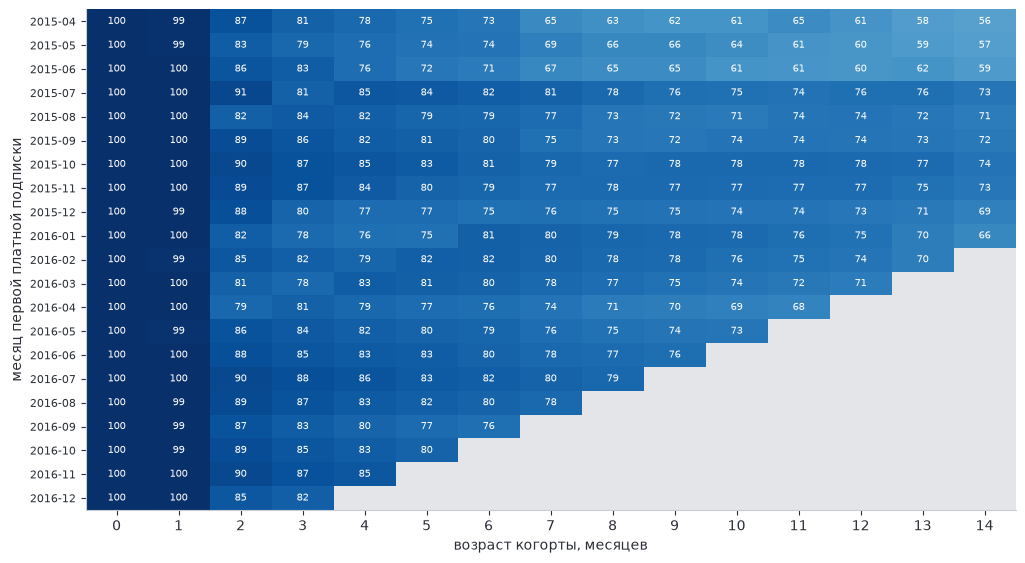

In [6]:
HEAT_FROM, HEAT_TO, HEAT_AGES = "2015-04-01", "2016-12-01", 14
heat = con.sql(f'''
    WITH coh AS (
        SELECT
            msno,
            first_paid_month AS cohort
        FROM anc
        WHERE first_paid_month BETWEEN DATE '{HEAT_FROM}' AND DATE '{HEAT_TO}'
    ),
    cohort_size AS (
        SELECT
            cohort,
            count(*) AS size
        FROM coh
        GROUP BY 1
    )
    SELECT
        coh.cohort,
        date_diff('month', coh.cohort, act.month) AS age,
        count(*)::DOUBLE / any_value(cohort_size.size) AS share
    FROM coh
    JOIN act USING (msno)
    JOIN cohort_size ON cohort_size.cohort = coh.cohort
    WHERE act.month >= coh.cohort
        AND date_diff('month', coh.cohort, act.month) <= {HEAT_AGES}
    GROUP BY coh.cohort, 2
''').df()
grid = heat.pivot(index="cohort", columns="age", values="share").reindex(columns=range(HEAT_AGES + 1))
observed = np.array([[(c + pd.DateOffset(months=a)) <= LAST_MONTH for a in grid.columns] for c in grid.index])
grid = grid.where(~observed | grid.notna(), 0.0).where(observed)

fig, ax = plt.subplots(figsize=(12, 6.5))
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#e3e5e9")
ax.imshow(np.ma.masked_invalid(grid.values), cmap=cmap, vmin=0, vmax=1, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.55 else INK)
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), [c.strftime("%Y-%m") for c in grid.index], fontsize=8)
ax.set_xlabel("возраст когорты, месяцев")
ax.set_ylabel("месяц первой платной подписки")
ax.grid(False)
plt.show()

## Выводы
- **Привязка к регистрации** даёт плоскую кривую 14–17% на всех возрастах: действующую подписку имеет лишь небольшая доля зарегистрированных, основная масса регистраций подписку не оформляет.
- **Первая подписка и первая платная подписка** расходятся из-за пробных периодов: к 3-му месяцу активны 61,6% когорты первой подписки и 82,4% когорты первой платной подписки. Для вопросов об удержании платящих клиентов привязка к первой платной подписке корректнее.
- **Клиенты без профиля в `members`** составляют 31% когорты первой подписки (217 757 из 706 644). Платили хотя бы раз 39% из них, среди остальных около 90%. Активны в 12-м месяце 28% против 67–69%. Удержание клиентов, зарегистрированных до 2015 года и с 2015 года, почти одинаково, поэтому разницу между вариантами «все» и «зарегистрированы с 2015» создают именно клиенты без профиля, а не возраст регистрации. Причина отсутствия профиля не установлена.
- **Левое цензурирование** заметно только в самых ранних когортах: в январе 2015 года 97,5% первых подписок (536 тыс. клиентов) приходится на клиентов, зарегистрированных до 2015 года. Когорты апреля–июня 2015 года удерживаются хуже (около 60% к 12-му месяцу), чем июля–декабря 2015 (73–78%). Поэтому когортный анализ начинается с июля 2015 года.
- **Строгое удержание и удержание с возвратами**: через 12 месяцев для первой платной подписки 64,2% против 74,4%, то есть 10,2 п. п. клиентов уходили и возвращались. Для первой подписки 47,5% против 55,7%.
- **Особенность определения**: на возрасте 1 активны почти 100%, потому что подписка на 30 дней затрагивает два календарных месяца. Реальное падение видно с возраста 2.
- **Ограничение**: отмены (3,9% строк транзакций) в расчёте активности не учитываются, поэтому активность слегка завышена.